# Lab 1 - A Simple Fingerprint Biometric System
 
**Name:** Taghrood
 
**Student ID:** 2316741



In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import fp_tools as fp          # our helper file
 
DATA = "fingerprint_data"
files = sorted(os.listdir(DATA))
print("Number of images:", len(files))
print("First five:", files[:5])



Number of images: 43
First five: ['.ipynb_checkpoints', 'P01_1.png', 'P01_2.png', 'P01_3.png', 'P01_4.png']


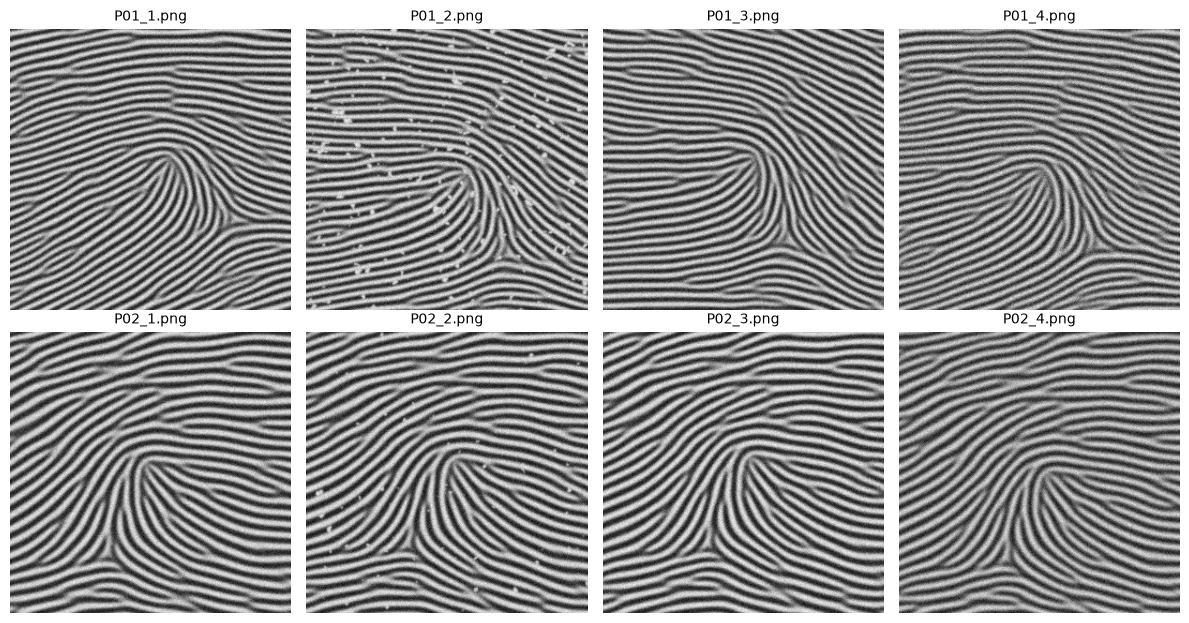

In [2]:
paths = [f"{DATA}/P01_{k}.png" for k in range(1, 5)] + [f"{DATA}/P02_{k}.png" for k in range(1, 5)]
fp.show_images(paths, cols=4)



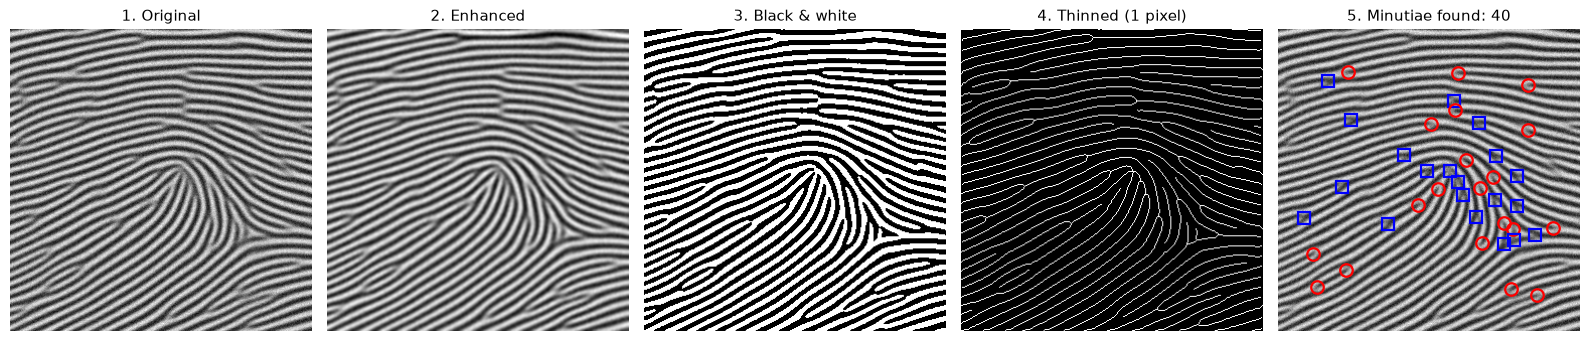

In [3]:
minutiae = fp.show_pipeline(f"{DATA}/P01_1.png")



In [4]:
print("Table shape (rows, columns):", minutiae.shape)
print("First three minutiae [x, y, angle, type]:")
print(np.round(minutiae[:3], 2))
print("Ridge endings   :", int((minutiae[:, 3] == 0).sum()))
print("Bifurcations    :", int((minutiae[:, 3] == 1).sum()))


Table shape (rows, columns): (40, 4)
First three minutiae [x, y, angle, type]:
[[6.90e+01 4.20e+01 2.95e+00 0.00e+00]
 [1.78e+02 4.30e+01 5.00e-02 0.00e+00]
 [4.90e+01 5.10e+01 2.99e+00 1.00e+00]]
Ridge endings   : 20
Bifurcations    : 20


In [5]:
database = {}
for person in range(1, 11):
    person_id = f"P{person:02d}"
    database[person_id] = fp.extract_template(f"{DATA}/{person_id}_1.png")
 
for person_id, template in database.items():
    print(person_id, "->", len(template), "minutiae")


P01 -> 40 minutiae
P02 -> 36 minutiae
P03 -> 50 minutiae
P04 -> 41 minutiae
P05 -> 23 minutiae
P06 -> 47 minutiae
P07 -> 44 minutiae
P08 -> 58 minutiae
P09 -> 42 minutiae
P10 -> 53 minutiae


In [6]:
to_save = {pid: t.tolist() for pid, t in database.items()}
with open("templates.json", "w") as f:
    json.dump(to_save, f)
print("Saved", len(to_save), "templates to templates.json")



Saved 10 templates to templates.json


In [7]:
probe_genuine = fp.extract_template(f"{DATA}/P01_2.png")
probe_impostor = fp.extract_template(f"{DATA}/P02_2.png")
 
score_g, pairs_g = fp.match(database["P01"], probe_genuine)
score_i, pairs_i = fp.match(database["P01"], probe_impostor)
print("Genuine  (P01 vs P01): paired =", len(pairs_g), " score = %.1f" % score_g)
print("Impostor (P01 vs P02): paired =", len(pairs_i), " score = %.1f" % score_i)



Genuine  (P01 vs P01): paired = 29  score = 25.3
Impostor (P01 vs P02): paired = 8  score = 3.8


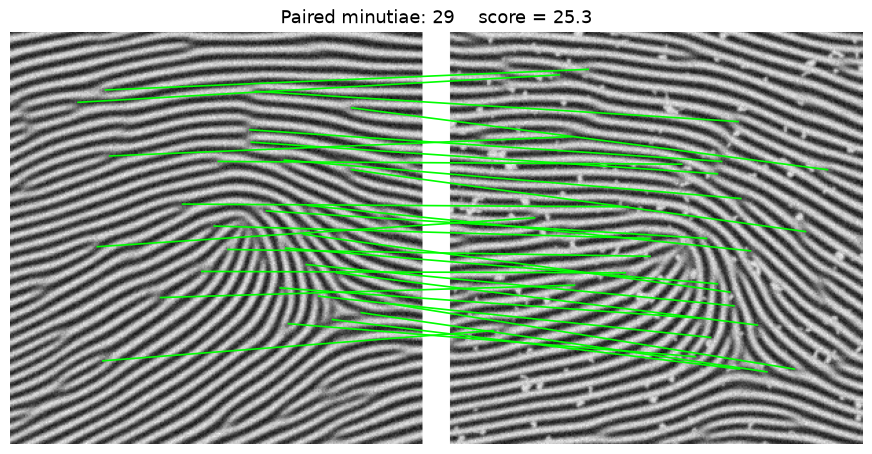

In [8]:
fp.show_match(f"{DATA}/P01_1.png", f"{DATA}/P01_2.png", database["P01"], probe_genuine, pairs_g, score_g)



In [9]:
THRESHOLD = 12
 
def verify(claimed_id, probe_path, threshold=THRESHOLD):
    probe = fp.extract_template(probe_path)
    score, pairs = fp.match(database[claimed_id], probe)
    decision = "ACCEPT" if score >= threshold else "REJECT"
    return decision, round(score, 1)
 
print("Real P03   :", verify("P03", f"{DATA}/P03_2.png"))
print("Real P03   :", verify("P03", f"{DATA}/P03_4.png"))
print("Impostor   :", verify("P03", f"{DATA}/P07_2.png"))
print("Impostor   :", verify("P03", f"{DATA}/S01_1.png"))



Real P03   : ('ACCEPT', 45.5)
Real P03   : ('ACCEPT', 79.0)
Impostor   : ('REJECT', 2.5)
Impostor   : ('REJECT', 6.1)


When THRESHOLD is changed to 50, the real scans are rejected because the matching score is lower than the high threshold.

In [10]:
def identify(probe_path, threshold=THRESHOLD):
    probe = fp.extract_template(probe_path)
    best_id, best_score = None, 0
    for person_id, template in database.items():
        score, _ = fp.match(template, probe)
        if score > best_score:
            best_id, best_score = person_id, score
    if best_score >= threshold:
        return best_id, round(best_score, 1)
    return "UNKNOWN", round(best_score, 1)
 
print(identify(f"{DATA}/P05_3.png"))
print(identify(f"{DATA}/P08_2.png"))
print(identify(f"{DATA}/S02_1.png"))


('P05', 62.8)
('P08', 47.1)
('UNKNOWN', 7.8)


In [11]:
genuine_scores, impostor_scores = [], []
for person in range(1, 11):
    pid = f"P{person:02d}"
    for k in (2, 3, 4):
        probe = fp.extract_template(f"{DATA}/{pid}_{k}.png")
        for other_id, template in database.items():
            score, _ = fp.match(template, probe)
            if other_id == pid:
                genuine_scores.append(score)
            else:
                impostor_scores.append(score)
 
genuine = np.array(genuine_scores)
impostor = np.array(impostor_scores)
print("Genuine comparisons :", len(genuine), "  average score = %.1f" % genuine.mean())
print("Impostor comparisons:", len(impostor), "  average score = %.1f" % impostor.mean())


Genuine comparisons : 30   average score = 60.4
Impostor comparisons: 270   average score = 3.4


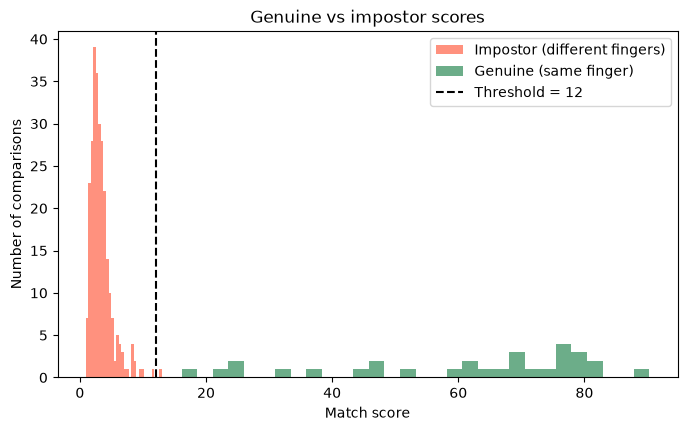

In [12]:
plt.figure(figsize=(8, 4.5))
plt.hist(impostor, bins=30, alpha=0.7, color="tomato", label="Impostor (different fingers)")
plt.hist(genuine, bins=30, alpha=0.7, color="seagreen", label="Genuine (same finger)")
plt.axvline(THRESHOLD, color="black", linestyle="--", label=f"Threshold = {THRESHOLD}")
plt.xlabel("Match score")
plt.ylabel("Number of comparisons")
plt.title("Genuine vs impostor scores")
plt.legend()
plt.savefig("score_histogram.png", dpi=150, bbox_inches="tight")
plt.show()



In [13]:
print("Threshold   FNMR (%)   FMR (%)")
for t in [5, 8, 10, 12, 15, 20, 30, 40]:
    fnmr = 100 * np.mean(genuine < t)
    fmr = 100 * np.mean(impostor >= t)
    print(f"{t:9d}   {fnmr:8.1f}   {fmr:7.2f}")



Threshold   FNMR (%)   FMR (%)
        5        0.0     11.85
        8        0.0      3.70
       10        0.0      1.11
       12        0.0      0.37
       15        0.0      0.00
       20        3.3      0.00
       30       13.3      0.00
       40       20.0      0.00


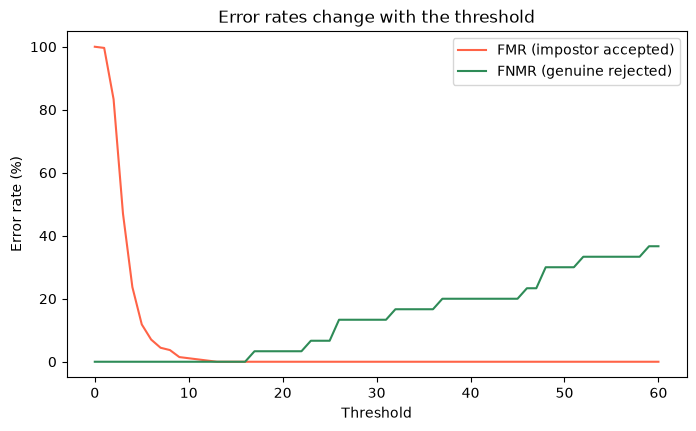

In [14]:
thresholds = np.arange(0, 61)
fmr_curve = [100 * np.mean(impostor >= t) for t in thresholds]
fnmr_curve = [100 * np.mean(genuine < t) for t in thresholds]
 
plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, fmr_curve, color="tomato", label="FMR (impostor accepted)")
plt.plot(thresholds, fnmr_curve, color="seagreen", label="FNMR (genuine rejected)")
plt.xlabel("Threshold")
plt.ylabel("Error rate (%)")
plt.title("Error rates change with the threshold")
plt.legend()
plt.savefig("error_curve.png", dpi=150, bbox_inches="tight")
plt.show()


## Part I. Choose a threshold
 
**Phone unlock (convenience):** threshold = 8 because ...
 
**Bank vault (security):** threshold = 20 because ...


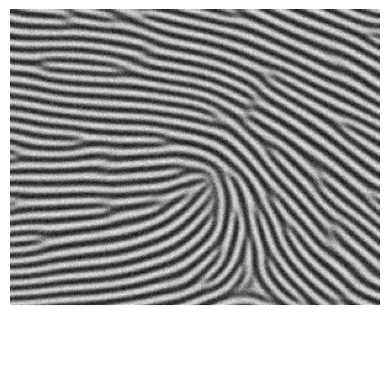

Half-covered genuine print: paired = 26  score = 42.2


In [15]:
img = fp.load_image(f"{DATA}/P01_3.png")
partial = fp.cover(img, 0.2)
plt.imshow(partial, cmap="gray"); plt.axis("off"); plt.show()
 
probe = fp.extract_template(partial)
score, pairs = fp.match(database["P01"], probe)
print("Half-covered genuine print: paired =", len(pairs), " score = %.1f" % score)



**Challenge Answer:**
* **Fraction test:** P01 stops being rejected when the covered fraction is reduced to **0.3** (or 0.2), because a larger portion of the fingerprint remains for matching.
* **Real-world solution:** Areal system can handle partical prints by asking the user to  press their finger again or guiding them to center their finger properly on the sensor.